# Exploratory Data Analysis (Honey)

**Datasets used**
- Primary Dataset 1: Student AI Tool Usage (200 students, survey)
- Primary Dataset 2: AI Student Impact (50,000 students)
- Secondary Dataset 2: Higher Education Students Performance (145 students, used in Step 4)

**Original research questions**
- Primary: How does student reliance on GenAI tools (weekly hours and tool diversity) relate to the change from pre-semester to post-semester GPA?
- Secondary: Do specific types of AI tasks (coding, writing, brainstorming) lead to higher satisfaction and completion rates compared to traditional study habits?

This notebook goes through the six EDA steps. Steps 5 ("so what?") and 6 ("what next?") are in the notes under each plot in Step 4, and the revised research questions are at the end.

## Step 1: Profile each primary dataset

For each primary dataset we look at the shape, the column types, the missing values, and the summary statistics.

In [1]:
import pandas as pd

df1 = pd.read_csv("data/student_ai_tool_usage_dataset.csv")
df2 = pd.read_csv("data/ai_student_impact_dataset (1).csv")

### Primary Dataset 1: Student AI Tool Usage

In [2]:
df1.shape

(200, 8)

In [3]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   timestamp             200 non-null    str  
 1   student_id            200 non-null    str  
 2   ai_tool_used          200 non-null    str  
 3   usage_hours_per_week  200 non-null    str  
 4   purpose               200 non-null    str  
 5   satisfaction_level    200 non-null    int64
 6   academic_performance  200 non-null    str  
 7   comments              190 non-null    str  
dtypes: int64(1), str(7)
memory usage: 12.6 KB


In [4]:
df1.isnull().sum()

timestamp                0
student_id               0
ai_tool_used             0
usage_hours_per_week     0
purpose                  0
satisfaction_level       0
academic_performance     0
comments                10
dtype: int64

In [5]:
df1.describe()

,satisfaction_level
count,200.000000
mean,3.770000
std,0.990964
min,1.000000
25%,3.000000
50%,4.000000
75%,5.000000
max,5.000000


In [6]:
# most columns here are text, so we also describe the text columns
df1.describe(exclude="number")

,timestamp,student_id,ai_tool_used,usage_hours_per_week,purpose,academic_performance,comments
count,200,200,200,200,200,200,190
unique,59,200,11,36,7,48,27
top,2026-03-14 18:00:00,HESC221102007,claude,14,study,Good,Helpful but sometimes inaccurate
freq,14,1,37,18,50,12,24


#### What stands out

- 10 rows have no comment. Maybe those students didn't have GenAI to help them write one :)
- Satisfaction is high: 117 of 200 students (58.5%) gave a 4 or 5 out of 5.
- `satisfaction_level` is the only number column. Everything else is text.
- Since it was a free-answer survey, we will need to clean up `ai_tool_used`, `purpose`, and `academic_performance` (e.g. "chatgpt" vs "ChatGPT", "study" vs "Study", and scores mixed with words like "Good").

### Primary Dataset 2: AI Student Impact

In [7]:
df2.shape

(50000, 16)

In [8]:
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  50000 non-null  int64  
 1   Major_Category              50000 non-null  str    
 2   Year_of_Study               50000 non-null  str    
 3   Pre_Semester_GPA            50000 non-null  float64
 4   Weekly_GenAI_Hours          50000 non-null  float64
 5   Primary_Use_Case            50000 non-null  str    
 6   Prompt_Engineering_Skill    50000 non-null  str    
 7   Tool_Diversity              50000 non-null  int64  
 8   Paid_Subscription           50000 non-null  bool   
 9   Traditional_Study_Hours     50000 non-null  float64
 10  Perceived_AI_Dependency     50000 non-null  int64  
 11  Institutional_Policy        50000 non-null  str    
 12  Anxiety_Level_During_Exams  50000 non-null  int64  
 13  Post_Semester_GPA           50000 non-null

In [9]:
df2.isnull().sum()

Student_ID                    0
Major_Category                0
Year_of_Study                 0
Pre_Semester_GPA              0
Weekly_GenAI_Hours            0
Primary_Use_Case              0
Prompt_Engineering_Skill      0
Tool_Diversity                0
Paid_Subscription             0
Traditional_Study_Hours       0
Perceived_AI_Dependency       0
Institutional_Policy          0
Anxiety_Level_During_Exams    0
Post_Semester_GPA             0
Skill_Retention_Score         0
Burnout_Risk_Level            0
dtype: int64

In [10]:
df2.describe()

,Student_ID,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score
count,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,125000.500000,3.146102,8.427752,2.80026,11.209271,3.505360,4.270760,3.349299,75.798125
std,14433.901067,0.478854,8.269490,1.18802,5.156426,1.820812,2.144066,0.495673,13.281626
min,100001.000000,1.183000,0.000000,1.00000,1.000000,1.000000,1.000000,1.000000,10.780000
25%,112500.750000,2.834000,2.390000,2.00000,7.560000,2.000000,3.000000,3.023750,66.820000
50%,125000.500000,3.210000,5.800000,3.00000,11.180000,3.000000,4.000000,3.421000,76.000000
75%,137500.250000,3.521000,11.720000,4.00000,14.710000,5.000000,6.000000,3.749000,85.190000
max,150000.000000,3.998000,40.000000,5.00000,35.860000,10.000000,10.000000,4.000000,100.000000


In [11]:
df2.describe(exclude="number")

,Major_Category,Year_of_Study,Primary_Use_Case,Prompt_Engineering_Skill,Paid_Subscription,Institutional_Policy,Burnout_Risk_Level
count,50000,50000,50000,50000,50000,50000,50000
unique,5,5,5,3,2,3,3
top,STEM,Junior,Debugging/Troubleshooting,Beginner,False,Allowed_With_Citation,Medium
freq,15059,11045,12295,18495,28846,25224,21144


#### What stands out

- No missing values at all. Every row is filled in.
- Average GPA only goes up by about 0.2 (3.15 before, 3.35 after). Less of a jump than we expected from using AI.
- Exam anxiety is lower than we expected: the average is about 4.3 out of 10. We thought heavy AI users might be more stressed, but that doesn't show up here.
- STEM is the biggest major, with about 15,000 students (30%). Junior is the most common year, with Freshman almost tied.
- The top use case is Debugging/Troubleshooting, which makes sense with so many STEM students who code.
- Surprising: more than half the students (57.7%) don't have a paid subscription.

## Step 2: Anomalies

We look for missing values, duplicates, inconsistent formatting, wrong data types, and invalid values. For each one we note how many rows it affects and what we did about it.

### Dataset 1: Student AI Tool Usage

**Duplicates**

In [12]:
df1.duplicated().sum()

np.int64(0)

**AI tool names are not consistent** (`chatgpt` vs `ChatGPT`, `ClaudeAi` vs `claude`).

In [13]:
df1["ai_tool_used"].value_counts()

ai_tool_used
claude      37
chatgpt     37
gemini      32
deepseek    30
copilot     30
ChatGPT     27
Gemini       2
DeepSeek     2
ClaudeAi     1
Copilot      1
Claude       1
Name: count, dtype: int64

In [14]:
df1["ai_tool_used"] = df1["ai_tool_used"].str.lower().str.strip()
df1["ai_tool_used"] = df1["ai_tool_used"].replace("claudeai", "claude")
df1["ai_tool_used"].value_counts()

ai_tool_used
chatgpt     64
claude      39
gemini      34
deepseek    32
copilot     31
Name: count, dtype: int64

**Purpose is not consistent** (`study` vs `Study`), and one answer is a full sentence.

In [15]:
df1["purpose"].value_counts()

purpose
study                                        50
writing                                      43
research                                     37
coding                                       36
Study                                        30
Coding                                        3
ChatGPT is used for many different tasks.     1
Name: count, dtype: int64

In [16]:
df1["purpose"] = df1["purpose"].str.lower().str.strip()
df1["purpose"] = df1["purpose"].replace("chatgpt is used for many different tasks.", "other")
df1["purpose"].value_counts()

purpose
study       80
writing     43
coding      39
research    37
other        1
Name: count, dtype: int64

**Usage hours are stored as text.** Most are plain numbers, but some have units (`7 hours`, `14hr`), some are ranges (`2-3 hours`), and some are words (`Unlimited`). We fix the ones with units. `pd.to_numeric(..., errors="coerce")` turns everything that is still not a number into a missing value (NaN).

In [17]:
hours = pd.to_numeric(df1["usage_hours_per_week"], errors="coerce")
df1.loc[hours.isnull(), "usage_hours_per_week"]

4                          Everytime 
5                       4 or 6 hours 
6                     20 hours may be
7                           2-3 hours
11                            7 hours
13                              10hrs
15                              40-50
17                            8 to 10
18                         Unlimited 
19                             1 hour
20                       2 to 3 hours
21                           4,hours 
23                               24 h
24                           3 Hours 
25                          2-3 hours
27                       3 to 4 hours
28                               14hr
32    Limited in paper otherwise rare
33                             1 hour
Name: usage_hours_per_week, dtype: str

In [18]:
unit_fixes = {
    "7 hours": "7",
    "10hrs": "10",
    "1 hour": "1",
    "24 h": "24",
    "3 hours": "3",
    "14hr": "14",
    "4,hours": "4",
}
df1["usage_hours_per_week"] = df1["usage_hours_per_week"].str.lower().str.strip().replace(unit_fixes)
df1["usage_hours_per_week"] = pd.to_numeric(df1["usage_hours_per_week"], errors="coerce")
df1["usage_hours_per_week"].isnull().sum()

np.int64(11)

**Academic performance mixes numbers and words** (`75`, `Good`, `Yes`). Words can't be turned into a score, so they become missing.

In [19]:
perf = pd.to_numeric(df1["academic_performance"], errors="coerce")
df1.loc[perf.isnull(), "academic_performance"].value_counts()

academic_performance
Good             12
Good              9
Average           2
Best              2
Yes               1
yes               1
Better            1
Great             1
Improved          1
just satsifed     1
Moderate          1
Excellent         1
Better            1
Name: count, dtype: int64

In [20]:
df1["academic_performance"] = perf
df1["academic_performance"].isnull().sum()

np.int64(34)

**Missing comments.** 10 students left the comment empty. We leave these as they are because comments are not part of our research questions.

In [21]:
df1["comments"].isnull().sum()

np.int64(10)

### Dataset 2: AI Student Impact

**Duplicates.** We check for duplicate rows and duplicate student IDs.

In [22]:
df2.duplicated().sum()

np.int64(0)

In [23]:
df2["Student_ID"].duplicated().sum()

np.int64(0)

**AI use under a strict ban.** We check how many students at schools with a strict AI ban still use AI.

In [24]:
strict = df2[df2["Institutional_Policy"] == "Strict_Ban"]
len(strict)

9788

In [25]:
(strict["Weekly_GenAI_Hours"] > 0).sum()

np.int64(9785)

### Anomaly summary

**Dataset 1: Student AI Tool Usage**

- `ai_tool_used` had different spellings and capitals. We normalized everything to lowercase (and `claudeai` → `claude`). Affected 34 rows.
- `purpose` had different spellings and capitals, and one answer was a full sentence. We normalized it to lowercase (the sentence became `other`). Affected 34 rows.
- `usage_hours_per_week` was stored as text. Affected 19 rows. We fixed 8 that had units by hand, and set 11 to missing because they were ranges or words.
- `academic_performance` had a mix of numbers and words. Affected 34 rows. We set all the words to missing, so the whole column is now numbers.
- 10 rows had missing `comments`. We left them as is because comments are not part of our research questions.

**Dataset 2: AI Student Impact**

- No duplicate rows or duplicate student IDs.
- No missing values.
- Interesting finding: at schools with a strict AI ban, almost every student still uses AI (9,785 of 9,788).

## Step 3: Distributions

One plot for each feature that matters to our research questions, with a note on its shape (center, spread, skew, outliers).

In [26]:
import matplotlib.pyplot as plt

plt.rcParams["font.size"] = 12

### Dataset 1: Student AI Tool Usage

**AI tool used**

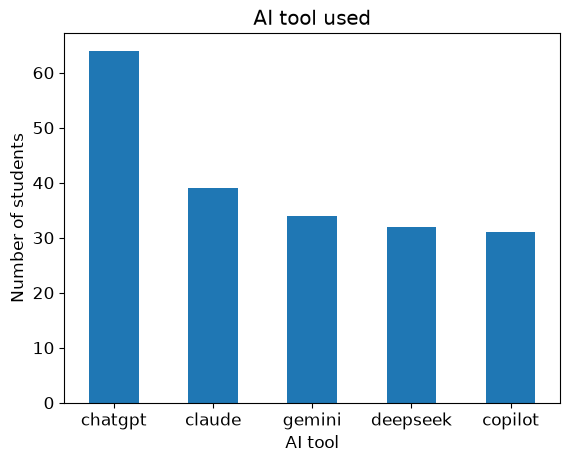

In [27]:
df1["ai_tool_used"].value_counts().plot(kind="bar")
plt.title("AI tool used")
plt.xlabel("AI tool")
plt.ylabel("Number of students")
plt.xticks(rotation=0)
plt.show()

**Shape:** Claude, Gemini, DeepSeek and Copilot are fairly even (31 to 39 students each). ChatGPT takes the edge with 64, almost 2 times the average of the other four (34).

**Purpose**

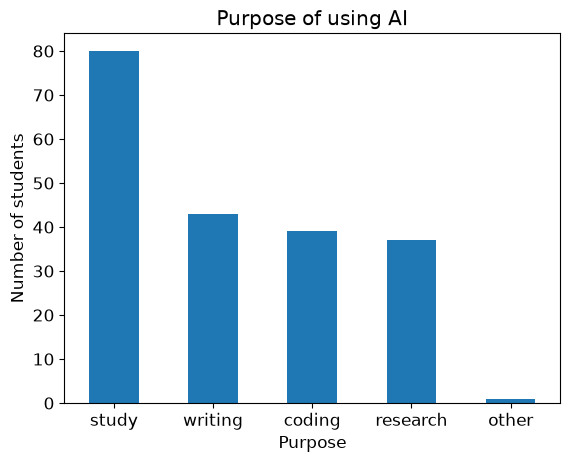

In [28]:
df1["purpose"].value_counts().plot(kind="bar")
plt.title("Purpose of using AI")
plt.xlabel("Purpose")
plt.ylabel("Number of students")
plt.xticks(rotation=0)
plt.show()

**Shape:** Study is the top purpose (80 students), about twice as many as any other. Writing, coding and research are close to each other (37 to 43), and only 1 student is "other".

**Usage hours per week** (the 11 missing values are left out)

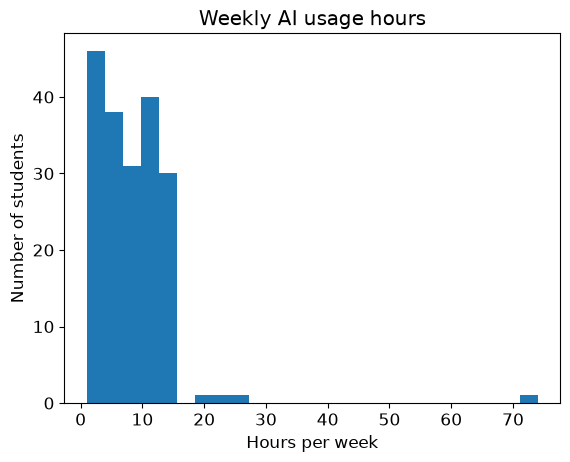

In [29]:
plt.hist(df1["usage_hours_per_week"].dropna(), bins=25)
plt.title("Weekly AI usage hours")
plt.xlabel("Hours per week")
plt.ylabel("Number of students")
plt.show()

**Shape:** Right-skewed. Most students use AI 1 to 15 hours a week, and almost all are under 25. One student reported 70+ hours, an outlier that may be a fake entry.

**Academic performance** (the 34 missing values are left out)

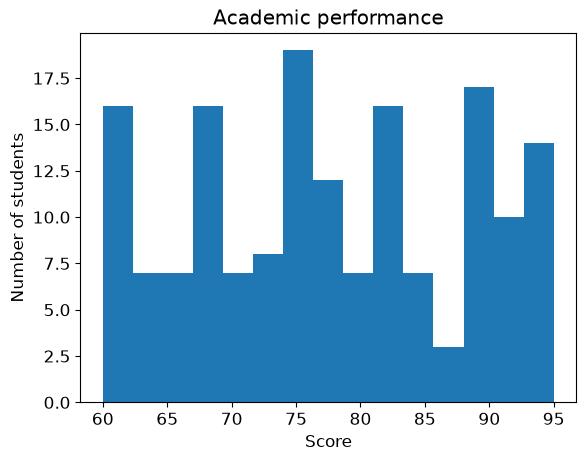

In [30]:
plt.hist(df1["academic_performance"].dropna(), bins=15)
plt.title("Academic performance")
plt.xlabel("Score")
plt.ylabel("Number of students")
plt.show()

**Shape:** Scores vary from 60 to 95 and are spread fairly evenly, with no clear peak. A well-balanced histogram.

**Satisfaction level** (1 = low, 5 = high)

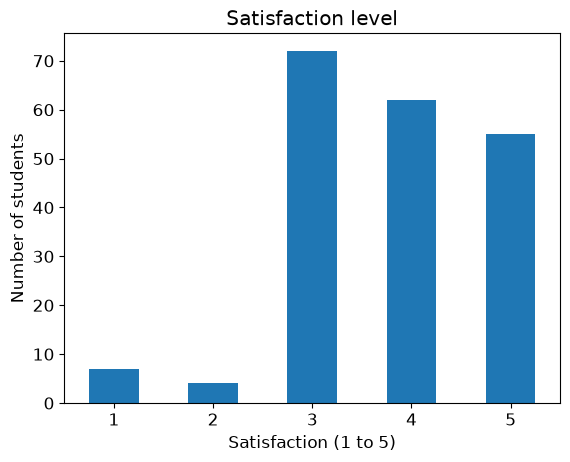

In [31]:
df1["satisfaction_level"].value_counts().sort_index().plot(kind="bar")
plt.title("Satisfaction level")
plt.xlabel("Satisfaction (1 to 5)")
plt.ylabel("Number of students")
plt.xticks(rotation=0)
plt.show()

**Shape:** Left-skewed (most answers are high, with a tail toward low scores). Almost all students gave a 3 or more; only 11 gave a 1 or 2.

### Dataset 2: AI Student Impact

**Weekly GenAI hours**

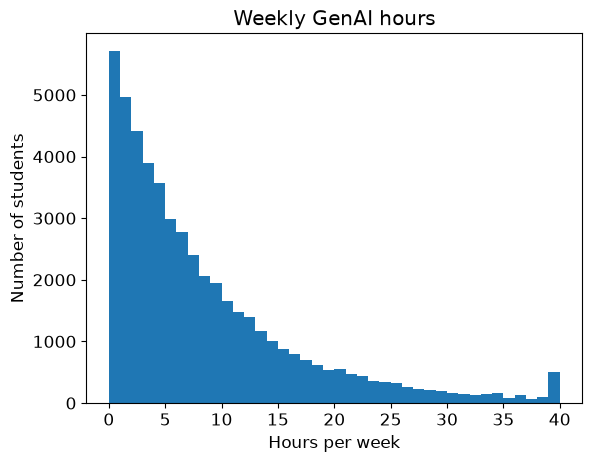

In [32]:
plt.hist(df2["Weekly_GenAI_Hours"], bins=40)
plt.title("Weekly GenAI hours")
plt.xlabel("Hours per week")
plt.ylabel("Number of students")
plt.show()

**Shape:** Strongly right-skewed. The number of students drops quickly as hours go up, and 90% use AI less than 20 hours a week. There is a small spike at exactly 40 hours.

**Tool diversity** (how many different AI tools a student uses)

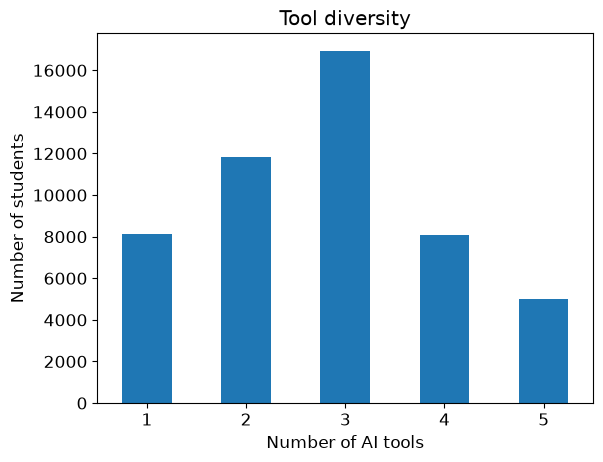

In [33]:
df2["Tool_Diversity"].value_counts().sort_index().plot(kind="bar")
plt.title("Tool diversity")
plt.xlabel("Number of AI tools")
plt.ylabel("Number of students")
plt.xticks(rotation=0)
plt.show()

**Shape:** Roughly bell-shaped. Most students use 3 AI tools, and about 5,000 use all 5.

**Pre- and post-semester GPA** (on the same plot so we can compare them)

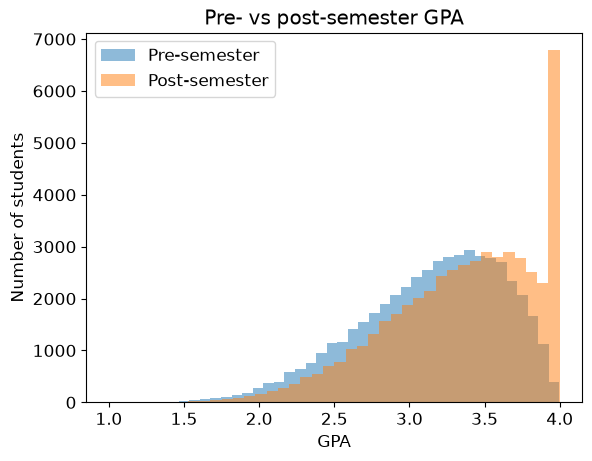

In [34]:
plt.hist(df2["Pre_Semester_GPA"], bins=40, alpha=0.5, label="Pre-semester")
plt.hist(df2["Post_Semester_GPA"], bins=40, alpha=0.5, label="Post-semester")
plt.title("Pre- vs post-semester GPA")
plt.xlabel("GPA")
plt.ylabel("Number of students")
plt.legend()
plt.show()

**Shape:** Both are left-skewed (bunched near the top, with a tail toward low GPAs). The post-semester curve is shifted to the right, so most students' GPA went up. There is a big spike at 4.0 after the semester because GPA can't go higher.

**GPA change** (post-semester GPA minus pre-semester GPA). Above 0 means the GPA went up.

In [35]:
df2["GPA_Change"] = df2["Post_Semester_GPA"] - df2["Pre_Semester_GPA"]
df2["GPA_Change"].describe()

count    50000.000000
mean         0.203197
std          0.187192
min         -0.924000
25%          0.087000
50%          0.204000
75%          0.325000
max          1.008000
Name: GPA_Change, dtype: float64

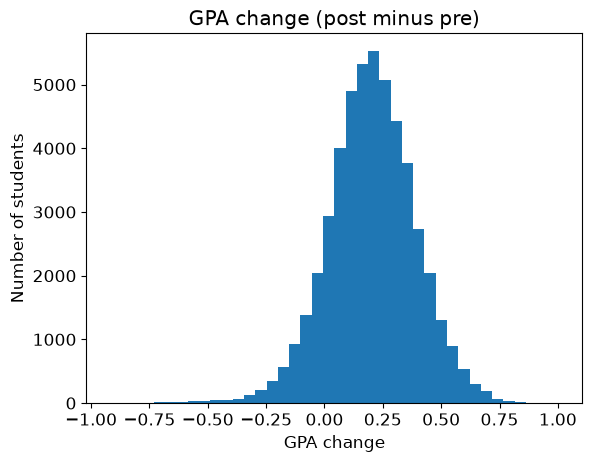

In [36]:
plt.hist(df2["GPA_Change"], bins=40)
plt.title("GPA change (post minus pre)")
plt.xlabel("GPA change")
plt.ylabel("Number of students")
plt.show()

**Shape:** Bell-shaped and centered around +0.2. Majority of students changed between 0.0 and +0.5, and only about 12% went down. So students improved a little, not a lot.

**Primary use case**

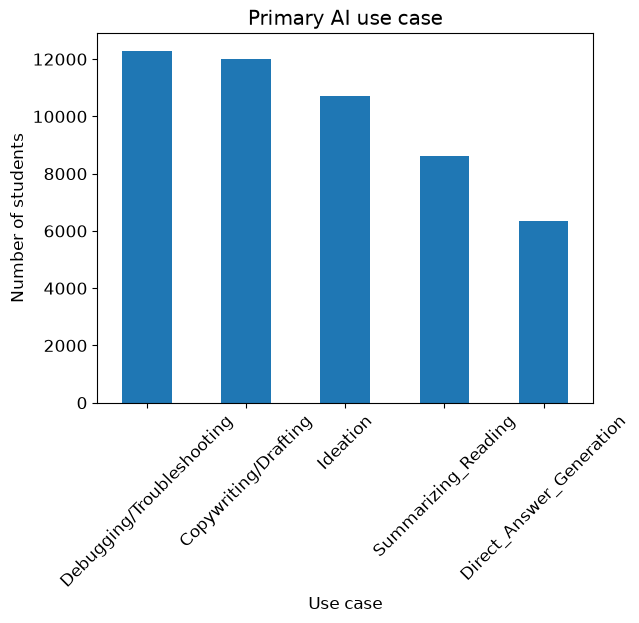

In [37]:
df2["Primary_Use_Case"].value_counts().plot(kind="bar")
plt.title("Primary AI use case")
plt.xlabel("Use case")
plt.ylabel("Number of students")
plt.xticks(rotation=45)
plt.show()

**Traditional study hours**

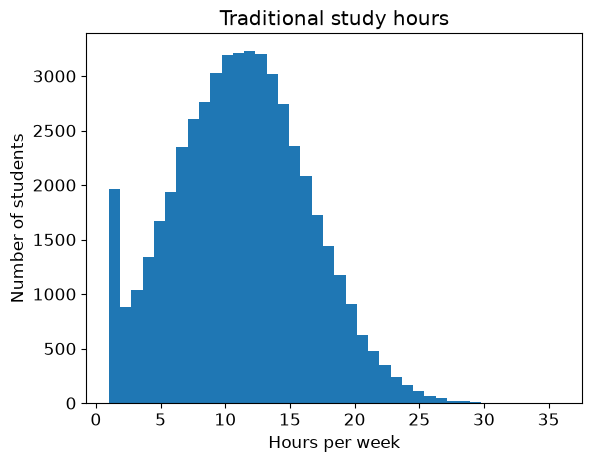

In [38]:
plt.hist(df2["Traditional_Study_Hours"], bins=40)
plt.title("Traditional study hours")
plt.xlabel("Hours per week")
plt.ylabel("Number of students")
plt.show()

**Shape:** Roughly bell-shaped, centered around 11 to 12 hours, and most students study 5 to 17 hours a week. There is an unusual spike at the low end: about 2,000 students study less than 2 hours a week, which is concerning.

## Step 4: Relationships

Plots that relate two or more features, chosen with our research questions in mind. Under each plot: what it shows, "so what?" (Step 5), and "what next?" (Step 6).

### Plot 1: Weekly GenAI hours vs GPA change (Dataset 2)

Does using AI more go with a bigger GPA change? The dots are small and see-through because 50,000 points overlap. Note: two things moving together doesn't mean one causes the other.

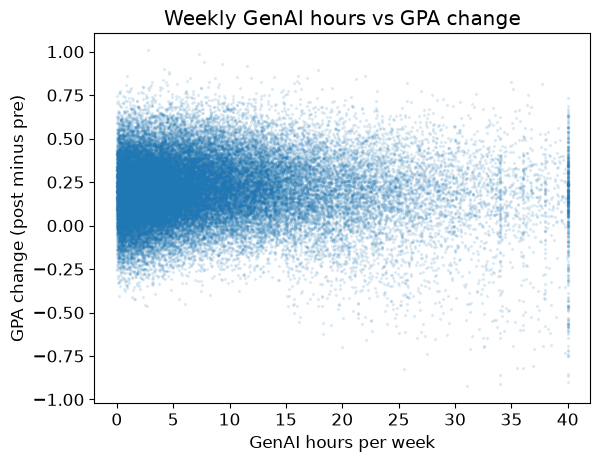

In [39]:
plt.scatter(df2["Weekly_GenAI_Hours"], df2["GPA_Change"], s=2, alpha=0.1)
plt.title("Weekly GenAI hours vs GPA change")
plt.xlabel("GenAI hours per week")
plt.ylabel("GPA change (post minus pre)")
plt.show()

**What it shows:** No clear trend. The GPA change stays around the same small gain no matter how many hours students use AI. Heavy users are more spread out, with some big gains and some big drops.

**So what:** This goes against our main idea. We expected more AI use to go with a bigger change in GPA (up or down), so this was unexpected. Heavy users being all over the place is interesting: AI might help some students and hurt others.

**What next:** Split the heavy AI users by use case or prompt engineering skill to see who gains and who drops.

### Plot 2: GPA change by tool diversity (Dataset 2)

Do students who use more AI tools have a different GPA change?

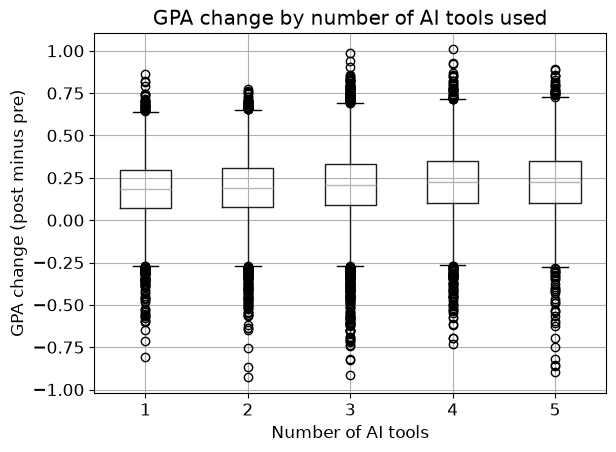

In [40]:
df2.boxplot(column="GPA_Change", by="Tool_Diversity")
plt.suptitle("")
plt.title("GPA change by number of AI tools used")
plt.xlabel("Number of AI tools")
plt.ylabel("GPA change (post minus pre)")
plt.show()

**What it shows:** The boxes look almost the same. The middle line goes up only a tiny bit as students use more tools.

**So what:** How many AI tools a student uses barely matters for GPA change. This was kind of expected, since using more tools doesn't mean using them well.

**What next:** Check whether prompt engineering skill matters more than the number of tools.

### Plot 3: Correlation matrix (Dataset 2)

How strongly each pair of features moves together, from -1 (opposite) to 1 (together). 0 means no relationship.

In [41]:
cols = ["Weekly_GenAI_Hours", "Tool_Diversity", "Traditional_Study_Hours",
        "Pre_Semester_GPA", "Post_Semester_GPA", "GPA_Change"]
corr = df2[cols].corr()
corr.round(2)

,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Pre_Semester_GPA,Post_Semester_GPA,GPA_Change
Weekly_GenAI_Hours,1.00,0.01,-0.16,-0.00,-0.02,-0.05
Tool_Diversity,0.01,1.00,0.00,-0.01,0.03,0.08
Traditional_Study_Hours,-0.16,0.00,1.00,-0.00,0.14,0.38
Pre_Semester_GPA,-0.00,-0.01,-0.00,1.00,0.93,-0.10
Post_Semester_GPA,-0.02,0.03,0.14,0.93,1.00,0.28
GPA_Change,-0.05,0.08,0.38,-0.10,0.28,1.00


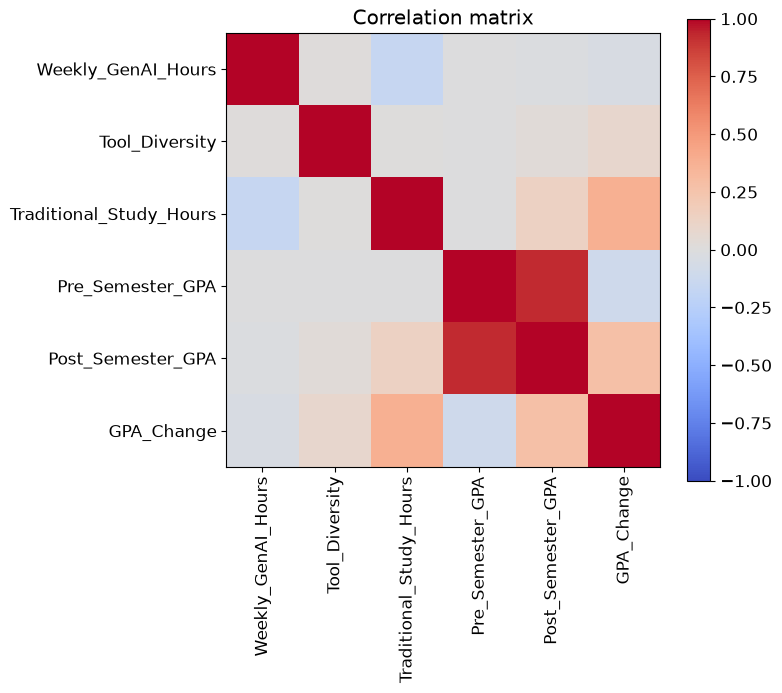

In [42]:
plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(cols)), cols, rotation=90)
plt.yticks(range(len(cols)), cols)
plt.title("Correlation matrix")
plt.show()

**What it shows:** Traditional study hours has the strongest link with GPA change. AI hours and tool diversity are close to zero. Students who use AI more tend to study a little less the traditional way. Pre and post GPA are strongly linked, which is expected.

**So what:** This was unexpected. Traditional studying, not AI, goes along with GPA improvement, which is a big deal for our main question. This only shows things moving together, not that studying causes the change.

**What next:** Compare subgroups: students with lots of AI and little studying vs students with lots of studying.

### Plot 4: Grade by weekly study hours (Secondary Dataset 2: Higher Education Students Performance)

In plot 3, traditional study hours had the strongest link to GPA change. Does the same thing show up in a different dataset of students? This dataset has no student IDs in common with ours, so we compare the pattern instead of joining.

Column `17` is weekly study hours (1 = none, 2 = under 5, 3 = 6-10, 4 = 11-20, 5 = more than 20). `GRADE` goes from 0 (fail) to 7 (AA).

In [43]:
s2 = pd.read_csv("data/higher_education_students_performance.csv")
s2["17"].value_counts().sort_index()

17
1    29
2    74
3    30
4     8
5     4
Name: count, dtype: int64

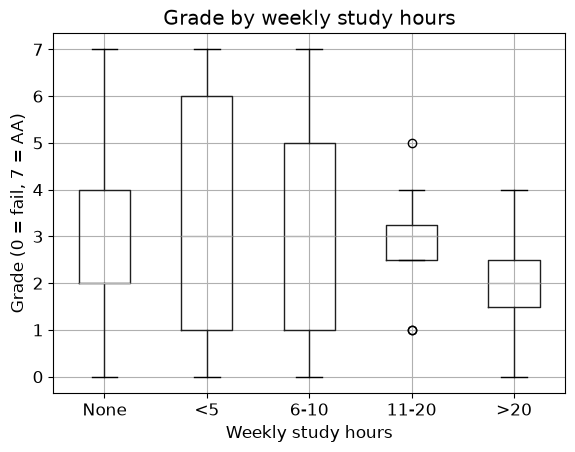

In [44]:
s2.boxplot(column="GRADE", by="17")
plt.suptitle("")
plt.xticks([1, 2, 3, 4, 5], ["None", "<5", "6-10", "11-20", ">20"])
plt.title("Grade by weekly study hours")
plt.xlabel("Weekly study hours")
plt.ylabel("Grade (0 = fail, 7 = AA)")
plt.show()

**What it shows:** In this dataset (students not focused on AI), more studying does not mean better grades. Students who study a little do about as well or better, and the groups who study the most are very small.

**So what:** This is the opposite of plot 3, so it was unexpected. But this dataset is small, and only a few students are in the high study groups, so we can't trust it much. It is also a different school and a different way of grading.

**What next:** Find a bigger dataset of students not using AI, or ask an instructor whether self-reported study hours are reliable.

## Step 6: Revised research questions

**Primary:** How do weekly AI hours and traditional study hours each relate to the change in students' GPA?

*What changed:* We added traditional study hours, because it turned out to matter much more than AI hours or tool diversity.

**Secondary:** Does the type of task students use AI for (coding, writing, studying, research) relate to how satisfied they are?

*What changed:* We dropped "session completion rates" and the comparison with traditional study habits. Traditional studying now lives in the primary question. Satisfaction only exists in Dataset 1 (not Dataset 2), so we focus on that.